# APID 130-133 exploration

Four APIDs with a handful of packets each: 130 (62 packets, mostly of 32 800 bytes), 131 (14, 48 bytes), 132 and 133 (about 99 each, 292 bytes). They were
found next to each other in the APID census (`find_apids.ipynb`). Questions:

1. What PUS service are they, and how do they relate to each other?
2. When do they appear (which dumps, which times, which cadence)?
3. What is in each of them?
4. Do they say anything about the Sun, SWAP or LYRA, or are they DSLP/TPMU?

In [1]:
import re
from collections import Counter, defaultdict
from datetime import UTC, datetime, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from cadu import iter_packets, packet_apid, packet_sequence_count

In [2]:
CADU_DIR = Path("cadus")
APIDS = (130, 131, 132, 133)

GPS_EPOCH = datetime(1980, 1, 6, tzinfo=UTC)
GPS_MINUS_TICK = 1_209_613_891  # GPS seconds minus tick, from APID_0.ipynb / APID_18.ipynb
MAX_TICK = 400_000_000  # ticks above this are bit errors

# Layout shared by all four (offsets into the whole packet, big-endian): primary header (6), PUS secondary header
# `10 <service> <subtype>` (6-8), 2 bytes (9-10), tick (11-14) and its fraction (15-16), data, CRC-16 (last 2 bytes).
SERVICE_OFFSET = 7
SUBTYPE_OFFSET = 8
TIME_OFFSET = 11
FRACTION_OFFSET = 15
CRC_LEN = 2

## 1. Load

In [3]:
packets: dict[int, list[tuple[str, int, bytes]]] = {apid: [] for apid in APIDS}  # (file name, vcid, packet)
others = Counter()
for path in sorted(CADU_DIR.glob("*.cadu")):
    for vcid, packet in iter_packets(path):
        apid = packet_apid(packet)
        if apid in packets:
            packets[apid].append((path.name, vcid, packet))
        elif 100 < apid < 200:
            others[apid] += 1
print("other APIDs between 100 and 200 (debris):", dict(others))
for apid, items in packets.items():
    print(
        f"APID {apid}: {len(items)} packets, virtual channels {dict(Counter(v for _, v, _ in items))}, "
        f"lengths {Counter(len(p) for _, _, p in items).most_common(4)}"
    )

other APIDs between 100 and 200 (debris): {161: 4, 197: 1, 193: 1, 114: 1, 187: 1, 155: 1, 165: 2, 146: 2, 115: 1, 123: 1, 170: 1, 172: 1, 136: 1, 139: 1, 112: 1, 103: 1, 152: 2, 104: 1, 156: 1, 173: 1, 171: 1, 175: 1, 144: 1, 108: 1, 195: 1, 148: 1, 185: 1}
APID 130: 62 packets, virtual channels {0: 61, 2: 1}, lengths [(32800, 54), (26183, 2), (23977, 1), (104, 1)]
APID 131: 14 packets, virtual channels {0: 14}, lengths [(48, 14)]
APID 132: 99 packets, virtual channels {0: 99}, lengths [(292, 98), (502, 1)]
APID 133: 98 packets, virtual channels {0: 98}, lengths [(292, 98)]


## 2. Headers

In [4]:
def crc16(data: bytes) -> int:
    """CRC-16/CCITT-FALSE."""
    crc = 0xFFFF
    for byte in data:
        crc ^= byte << 8
        for _ in range(8):
            crc = ((crc << 1) ^ 0x1021) & 0xFFFF if crc & 0x8000 else (crc << 1) & 0xFFFF
    return crc


def crc_ok(packet: bytes) -> bool:
    return crc16(packet[:-CRC_LEN]) == int.from_bytes(packet[-CRC_LEN:])


def tick_of(packet: bytes) -> float:
    return int.from_bytes(packet[TIME_OFFSET : TIME_OFFSET + 4]) + int.from_bytes(packet[FRACTION_OFFSET:][:2]) / 65536


def utc(tick: float) -> datetime:
    return GPS_EPOCH + timedelta(seconds=tick + GPS_MINUS_TICK)


for apid, items in packets.items():
    print(f"== APID {apid}")
    print("  secondary header + bytes 9-10:", Counter(p[6:11].hex() for _, _, p in items).most_common(3))
    print("  sequence flags:", Counter(p[2] >> 6 for _, _, p in items))
    print("  length field + 7 == length:", Counter(int.from_bytes(p[4:6]) + 7 == len(p) for _, _, p in items))
    print("  CRC-16 ok:", Counter(crc_ok(p) for _, _, p in items))

== APID 130
  secondary header + bytes 9-10: [('1006060000', 61), ('1003190001', 1)]
  sequence flags: Counter({3: 62})
  length field + 7 == length: Counter({True: 55, False: 7})
  CRC-16 ok: Counter({True: 39, False: 23})
== APID 131
  secondary header + bytes 9-10: [('1003190000', 14)]
  sequence flags: Counter({3: 14})
  length field + 7 == length: Counter({True: 14})
  CRC-16 ok: Counter({True: 14})
== APID 132
  secondary header + bytes 9-10: [('1003190000', 97), ('0903190000', 1), ('100319033a', 1)]
  sequence flags: Counter({3: 99})
  length field + 7 == length: Counter({True: 99})
  CRC-16 ok: Counter({True: 93, False: 6})
== APID 133
  secondary header + bytes 9-10: [('1003190000', 98)]
  sequence flags: Counter({3: 98})
  length field + 7 == length: Counter({True: 98})
  CRC-16 ok: Counter({True: 93, False: 5})


The secondary header is `10 <service> <subtype>` as in the other APIDs: **APID 130 is service 6, subtype 6 and APIDs 131, 132 and 133 are service 3, subtype 25**.
In the PUS (ECSS-E-70-41A) service 6 is *memory management*, subtype 6 the *memory dump report* (absolute addresses), and service 3 is *housekeeping and diagnostic data
reporting*, subtype 25 the *housekeeping parameter report*. Bytes 9-10 are `00 00` (the `00 01` marker of the verification reports is not here; the one packet with it is debris). The CRC-16 over the packet works (the failures are packets with lost frames or bit errors: the
dumps are not RS corrected). The length field of the 32 800 byte packets is `0x8019` = 32 793, the bytes past 32 767 are no problem for the demuxer.

## 3. When, and in what order

In [5]:
frames = []  # (apid, file, seq, tick, length, ok)
for apid, items in packets.items():
    for name, _, p in items:
        tick = tick_of(p)
        if tick < MAX_TICK and p[6] == 0x10:
            frames.append((apid, name, packet_sequence_count(p), tick, len(p), crc_ok(p)))

files = sorted({f[1] for f in frames}, key=lambda name: min(f[3] for f in frames if f[1] == name))
print(f"{'file':32s} {'start (UTC)':22s}  offsets in s from the first packet of the dump (APID: ticks)")
for name in files:
    mine = [f for f in frames if f[1] == name]
    start = min(f[3] for f in mine)
    parts = []
    for apid in APIDS:
        ticks = sorted(f[3] - start for f in mine if f[0] == apid)
        if ticks:
            parts.append(f"{apid}: " + ",".join(f"{t:.0f}" for t in ticks))
    print(f"{name:32s} {utc(start):%a %Y-%m-%d %H:%M:%S}  " + "  ".join(parts))

file                             start (UTC)             offsets in s from the first packet of the dump (APID: ticks)
proba2_dump(12).cadu             Fri 2025-08-08 03:40:47  130: 72,75,78,81,251,255,258,261  131: 84,264  132: 0,30,60,90,120,150,180,210,240,270  133: 0,30,60,90,120,150,180,210,240,270
proba2_dump(11).cadu             Sun 2025-08-10 03:33:20  130: 147,151,154,157  131: 160  132: 0,30,60,90,120,150,180,210,240,270  133: 0,30,60,90,120,150,180,210,240,270
proba2_dump(10).cadu             Thu 2025-08-14 16:53:56  130: 146,149,152,155  131: 159  132: 0,30,60,90,120,150,180,210,240  133: 0,30,60,90,120,150,180,210,240
proba2_dump(9).cadu              Sat 2025-08-16 03:12:58  130: 76,79,82,85  131: 89  132: 0,30,60,90,120,150  133: 0,30,60,90,120,150
proba2_dump(8).cadu              Sun 2025-08-17 03:56:14  130: 0,174,177,180,183  131: 186  132: 45,75,105,135,165,195,225,255,285  133: 45,75,105,135,165,195,225,255,285
proba2_dump(7).cadu              Mon 2025-08-18 03:06:01 

Each dump has the same pattern, in the same few minutes:

- **132 and 133 together, every 30 s**, 3 to 10 times (about 5 minutes);
- **130 (the memory dump) in a burst of four packets** 3 s apart, starting 24 to 147 s after the first 132 (the start varies) and in some dumps a second burst 180 s
  after the first;
- **131 once per burst**, 3 s after the last packet of the burst of 130.

132 and 133 have the same sequence counts and ticks, so they are the two halves of one report (probably two structures sent one after the other). All of this is in the dumps from
every day, including weekends, at 02:59-04:00 UTC and 16:42-17:20 UTC, i.e. in the ground contacts. In the two dumps where the APID 8 poll was recorded (`APID_8.ipynb`) it is
in the same minutes: in the main dump 132/133 start at 03:56:44, 130 at 03:57:08 and the APID 8 poll at 03:57:37; in dump 4 (2025-08-21) they are at 17:19:06, 17:19:43 and 17:19:52.
So these are plausibly the housekeeping reports and the memory dump of the same unit as APID 8 (the eclipse dump shows 2026 only because its tick offset is
different, see the README).

In [6]:
pair = defaultdict(dict)
for apid, name, seq, tick, length, _ in frames:
    if apid in (132, 133) and length == 292:
        pair[name, round(tick)][apid] = seq
print("132 and 133 with the same (file, tick):", Counter(tuple(sorted(item)) for item in pair.values()))
print(
    "... and the same sequence count:",
    Counter(item.get(132) == item.get(133) for item in pair.values() if len(item) == 2),
)
steps = Counter()
for name in files:
    ticks = sorted(f[3] for f in frames if f[1] == name and f[0] == 132)
    steps.update(np.round(np.diff(ticks)).astype(int).tolist())
print("seconds between 132 reports:", dict(steps.most_common(6)))

132 and 133 with the same (file, tick): Counter({(132, 133): 96, (133,): 2, (132,): 1})
... and the same sequence count: Counter({True: 96})
seconds between 132 reports: {30: 78, 60: 3, 90: 1, 29: 1}


## 4. APID 130: memory dump

The packets with 32 800 bytes: 17 bytes header, 4 zero bytes, then what looks like an address and a length.

In [7]:
dump = [p for _, _, p in packets[130] if len(p) == 32800]
print("bytes 17-30 (header of the memory report), distinct:")
for key, count in Counter(p[17:30].hex(" ") for p in dump).most_common():
    print(f"  {key}  {count}")
fields = Counter((p[21], int.from_bytes(p[22:26]), int.from_bytes(p[26:30])) for p in dump)
print(
    "(byte 21, address, length):",
    {(a, f"{b:#x}", f"{c:#x}"): n for (a, b, c), n in sorted(fields.items(), key=lambda item: item[0][1])},
)
print("packet = 30 + length + 2:", all(len(p) == 30 + int.from_bytes(p[26:30]) + 2 for p in dump))
shorter = [(n, len(p)) for n, _, p in packets[130] if len(p) != 32800]
print("the others (lost frames):", shorter)

bytes 17-30 (header of the memory report), distinct:
  00 00 00 00 01 00 00 80 00 00 00 80 00  14
  00 00 00 00 01 00 01 80 00 00 00 80 00  14
  00 00 00 00 01 00 01 00 00 00 00 80 00  13
  00 00 00 00 01 00 00 00 00 00 00 80 00  13
(byte 21, address, length): {(1, '0x0', '0x8000'): 13, (1, '0x8000', '0x8000'): 14, (1, '0x10000', '0x8000'): 13, (1, '0x18000', '0x8000'): 14}
packet = 30 + length + 2: True
the others (lost frames): [('proba2_dump(1).cadu', 23977), ('proba2_dump(1).cadu', 104), ('proba2_dump(3).cadu', 14728), ('proba2_dump(7).cadu', 26183), ('proba2_dump(8).cadu', 3894), ('proba2_dump(9).cadu', 30595), ('proba2_dump.cadu', 26183), ('proba2_dump.cadu', 9115)]


The 32 800 bytes are 17 bytes of the standard header, `00 00 00 00`, a byte `01` (the memory id), the **start address** (22-25: 0x0, 0x8000, 0x10000, 0x18000) and the **length**
(26-29: 0x8000 = 32 768) and the data, then the CRC: 30 + 32 768 + 2. So a burst of four packets is **128 KB of memory from address 0**, in four
pieces. Which memory it is shows in the contents.

In [8]:
chunks: dict[int, dict[str, bytes]] = defaultdict(dict)
for name, _, p in packets[130]:
    if len(p) == 32800 and crc_ok(p):
        chunks[int.from_bytes(p[22:26])][name] = p[30:-CRC_LEN]
print("pieces with a valid CRC per start address:", {f"{a:#x}": len(v) for a, v in sorted(chunks.items())})
all_pieces = defaultdict(list)
for _name, _, p in packets[130]:
    if len(p) == 32800:
        all_pieces[int.from_bytes(p[22:26])].append(np.frombuffer(p[30:-CRC_LEN], dtype=np.uint8))
for address, pieces in sorted(all_pieces.items()):
    reference = pieces[0]
    valid = [np.frombuffer(piece, dtype=np.uint8) for piece in chunks.get(address, {}).values()] or pieces
    same = [float((piece == valid[0]).mean()) for piece in valid[1:]] or [float("nan")]
    counts = np.bincount(reference, minlength=256)
    probability = counts[counts > 0] / counts.sum()
    valid_count = len(chunks.get(address, {}))
    equal = f"min {min(same):.3f} max {max(same):.3f}"
    zeros, ones = counts[0] / counts.sum(), counts[255] / counts.sum()
    entropy = -(probability * np.log2(probability)).sum()
    print(
        f"{address:#8x}: {len(pieces):2d} dumps ({valid_count} with a valid CRC), equal to the first one: {equal}; "
        f"0x00 {zeros:.0%}, 0xff {ones:.0%}, entropy {entropy:.2f} bit/byte"
    )

pieces with a valid CRC per start address: {'0x8000': 11, '0x10000': 11, '0x18000': 11}
     0x0: 13 dumps (0 with a valid CRC), equal to the first one: min 0.793 max 0.963; 0x00 9%, 0xff 29%, entropy 6.06 bit/byte
  0x8000: 14 dumps (11 with a valid CRC), equal to the first one: min 1.000 max 1.000; 0x00 2%, 0xff 2%, entropy 7.81 bit/byte
 0x10000: 13 dumps (11 with a valid CRC), equal to the first one: min 1.000 max 1.000; 0x00 63%, 0xff 0%, entropy 2.80 bit/byte
 0x18000: 14 dumps (11 with a valid CRC), equal to the first one: min 1.000 max 1.000; 0x00 63%, 0xff 0%, entropy 2.82 bit/byte


Over 7 weeks (2025-08-08 to 2025-10-10) the pieces at 0x8000, 0x10000 and 0x18000 with a valid CRC are **identical in every dump**, byte for byte: they are static memory, not a live
buffer. (Comparing all the pieces instead of the valid ones shows differences of up to 10 % in a few: those are pieces with lost frames.) The piece at 0x0 changes from one dump to the
next, and its CRC fails in *every* dump: a CRC computed before the memory changed while it was read out would explain that. This one is a live region.

In [9]:
first = all_pieces[0][0].tobytes()
RECORD_LEN = 16
RECORD_START = 2
records = [first[i : i + RECORD_LEN] for i in range(RECORD_START, len(first) - RECORD_LEN + 1, RECORD_LEN)]
marker = Counter(r[:3].hex() for r in records)
print("first 3 bytes of the 16 byte records (offset 2):", marker.most_common(4))
structured = next(i for i, r in enumerate(records) if i and r[:3] != b"\x00\x00\x01")
print("records that start with 00 00 01 (after the first one):", structured - 1)
print(
    "share of 0xff in the rest of the piece:",
    float((all_pieces[0][0][RECORD_START + RECORD_LEN * structured :] == 0xFF).mean()),
)
print()
for r in records[:12]:
    print(
        " ",
        r[:3].hex(" "),
        "|",
        r[3:7].hex(" "),
        "|",
        r[7:10].hex(" "),
        "|",
        r[10:14].hex(" "),
        "|",
        r[14:].hex(" "),
        " ",
        int.from_bytes(r[10:14]),
    )
stamps = np.array([int.from_bytes(r[10:14]) for r in records[:structured]])
print("increasing in", (np.diff(stamps) >= 0).mean(), "of the steps; from", stamps[0], "to", stamps[-1])

first 3 bytes of the 16 byte records (offset 2): [('ffffff', 554), ('000000', 116), ('000001', 64), ('010002', 8)]
records that start with 00 00 01 (after the first one): 62
share of 0xff in the rest of the piece: 0.2959254361105863

  01 24 01 | 00 00 0a df | 47 db c1 | 00 fa bd c7 | 01 1c   16432583
  00 00 01 | 00 00 08 7a | 47 dc 82 | 00 fa bd ff | bf e4   16432639
  00 00 01 | 00 00 02 11 | 47 db 82 | 00 fa bd ff | c0 40   16432639
  00 00 01 | 00 00 0a d6 | 47 db c2 | 00 fa be 0e | 07 88   16432654
  00 00 01 | 00 00 0a d6 | 47 db c2 | 00 fa be 0e | 07 b0   16432654
  00 00 01 | 00 00 0a d6 | 47 db c2 | 00 fa be 8c | 8d 6c   16432780
  00 00 01 | 00 00 0a ee | 47 db ca | 01 63 0d 67 | 67 20   23268711
  00 00 01 | 00 00 06 fb | 47 da ca | 01 8d 83 e6 | fd 20   26051558
  00 00 01 | 00 00 0a 3c | 47 da 8a | 01 8d 83 ee | 36 a0   26051566
  00 00 01 | 00 00 0a fb | 47 da ca | 01 8d 83 f9 | 58 10   26051577
  00 00 01 | 00 00 0a ee | 47 db ca | 01 8e 58 76 | 1f d0   26105974
  00 00

The piece at address 0 starts with 64 records of 16 bytes (the first 1 KB; the layout `00 00 01 | 4 bytes | 3 bytes | 4 byte counter | 2 bytes` fits the records
from offset 2, the very first one has another shape) and then a mix of `0xff` (29 % of the piece), `0x00` and noise: a **log or trace buffer** in front of an area that was erased to `0xff`. The 4 byte field
increases from record to record in 97 % of the steps (a time tag: 16 432 583, ..., 205 894 657; the last entry is smaller than the first, which would
be a ring buffer that wrapped), the 3 byte field repeats (`47 db ca`, `47 da ca`, `2f db ca`, `0f da 8a`...) and the 2 byte field next to it increases too. What it logs is not clear from this.

The pieces at 0x10000 and 0x18000 are 63 % zero words with a repeated pattern (`00 00 02 08` 1 293 times: 0x208 = 520), the piece at 0x8000 is
dense (7.8 bit/byte, not zeros, no readable text; the cell below checks for SPARC code): compressed or encoded data, a table or an image. 520 is 512 + 8, the size of a NAND flash page with its spare
area, which is a guess. The content cannot be told from these four pieces alone.

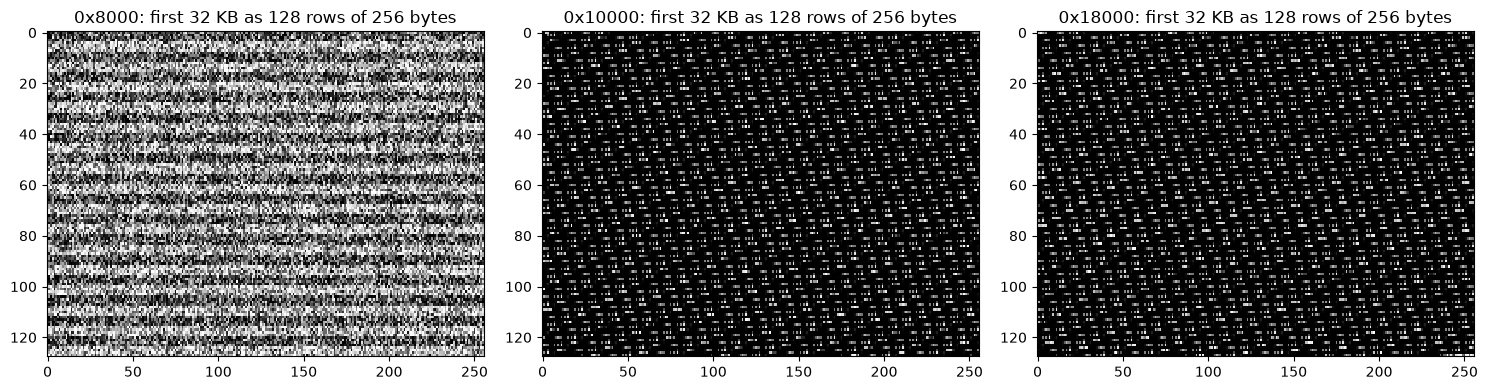

0x8000 piece: SPARC `save` (9d e3 bf): 0  `retl` (81 c3 e0 08): 0  `nop`: 0  printable runs of 8+ bytes: 7
share of bytes equal to the one n bytes before, at 0x10000: {4: 0.421, 8: 0.54, 260: 0.382, 520: 0.421, 1040: 0.448}


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, address in zip(axes, (0x8000, 0x10000, 0x18000), strict=True):
    piece = all_pieces[address][0]
    ax.imshow(piece[: 256 * 128].reshape(128, 256), cmap="gray", aspect="auto", interpolation="nearest")
    ax.set(title=f"{address:#x}: first 32 KB as 128 rows of 256 bytes")
plt.tight_layout()
plt.show()
piece = all_pieces[0x8000][0].tobytes()
print(
    "0x8000 piece: SPARC `save` (9d e3 bf):",
    piece.count(bytes.fromhex("9de3bf")),
    " `retl` (81 c3 e0 08):",
    piece.count(bytes.fromhex("81c3e008")),
    " `nop`:",
    piece.count(bytes.fromhex("01000000")),
    " printable runs of 8+ bytes:",
    len(re.findall(rb"[ -~]{8,}", piece)),
)
period = {p: float((all_pieces[0x10000][0][p:] == all_pieces[0x10000][0][:-p]).mean()) for p in (4, 8, 260, 520, 1040)}
print("share of bytes equal to the one n bytes before, at 0x10000:", {k: round(v, 3) for k, v in period.items()})

## 5. APID 131: 48 byte report

In [11]:
status = [p for _, _, p in packets[131]]
print(len(status), "packets, CRC ok:", Counter(crc_ok(p) for p in status))
print("byte: distinct values (most common)")
for i in range(17, 46):
    values = Counter(p[i] for p in status)
    if len(values) > 1:
        print(f"  {i}: {len(values)} values {values.most_common(4)}")
print(
    "constant bytes 17-45:",
    " ".join(f"{status[0][i]:02x}" if len({p[i] for p in status}) == 1 else ".." for i in range(17, 46)),
)

14 packets, CRC ok: Counter({True: 14})
byte: distinct values (most common)
  24: 2 values [(32, 13), (224, 1)]
  30: 5 values [(50, 7), (8, 3), (56, 2), (128, 1)]
  31: 5 values [(0, 5), (72, 4), (32, 2), (56, 2)]
  32: 3 values [(64, 11), (72, 2), (127, 1)]
  33: 2 values [(0, 13), (224, 1)]
  45: 2 values [(0, 13), (4, 1)]
constant bytes 17-45: 00 00 00 00 00 01 10 .. 00 00 00 3f ff .. .. .. .. 00 00 00 03 00 00 02 58 00 00 00 ..


Of the 29 bytes after the time stamp, almost all are constant: `00 00 00 00 00 01 10 20 00 00 00 3f ff` ... `03 00 00 02 58 00 00 00`. Only byte 24 (`0x20`, once `0xe0`), bytes 30-33
(four bytes that change a little: `32 00 40 00`, `08 48 40 00`, `38 20 40 00`...) and byte 45 vary. `0x0258` = 600 and `3fff` a 14 bit mask. It looks like a status or
configuration report of the unit with a few flags and one value, not like a measurement.

## 6. APIDs 132 and 133: 66 housekeeping values each

In [12]:
FIRST_WORD = 22
WORDS = 65  # channel words; one empty word and the 4 byte footer follow
good = {
    apid: [p for _, _, p in packets[apid] if len(p) == 292 and p[6:9].hex() == "100319" and crc_ok(p)]
    for apid in (132, 133)
}
print({apid: len(items) for apid, items in good.items()})
words = {}
for apid, items in good.items():
    flags = Counter(p[FIRST_WORD + 4 * k] for p in items for k in range(WORDS))
    channels = [Counter(p[FIRST_WORD + 1 + 4 * k] for p in items).most_common(1)[0][0] for k in range(WORDS)]
    values = np.array(
        [[int.from_bytes(p[FIRST_WORD + 2 + 4 * k : FIRST_WORD + 4 + 4 * k]) for k in range(WORDS)] for p in items]
    )
    words[apid] = values
    print(f"APID {apid}: first byte of the words {dict(flags)}")
    print("   second byte per position:", channels)
    footers = Counter(p[FIRST_WORD + 4 * (WORDS + 1) :][:4].hex() for p in items)
    print(f"   values: min {values.min()}, max {values.max()} (12 bit: {values.max() < 4096}); footer {footers}")
    print("   bytes 17-21:", Counter(p[17:22].hex() for p in items))

{132: 93, 133: 93}
APID 132: first byte of the words {128: 6045}
   second byte per position: [32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 32, 32, 32, 40, 35, 32, 35]
   values: min 1889, max 3437 (12 bit: True); footer Counter({'00000003': 93})
   bytes 17-21: Counter({'0000000000': 93})
APID 133: first byte of the words {128: 6045}
   second byte per position: [32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 33, 32, 33, 32, 32, 32, 40, 35, 32, 35]
   values: min 13, max 4042 (12 bit: True); footer Counter({'0000000c': 93})
   bytes 17-21: Counter({'0000000000': 93})


Each report is 17 bytes of header, 5 zero bytes and **65 words of 4 bytes: `80 <channel> <12 bit value>`** (93 reports x 65 words, all with the first byte `0x80`, a valid flag), an empty word
(`00 00 00 00`), a 4 byte footer (`00 00 00 03` for 132, `00 00 00 0c` for 133) and the CRC. The second byte is a channel group: `0x20` for most of the words, `0x21` for a block of 17
(words 41-57) and single words `0x28` and `0x23`. The values never exceed 4095 (max 3 437 and 4 042): **a 12 bit ADC**, 65 channels, one conversion round per report, so
132/133 are an **analog housekeeping scan** of the unit (voltages, currents, temperatures).

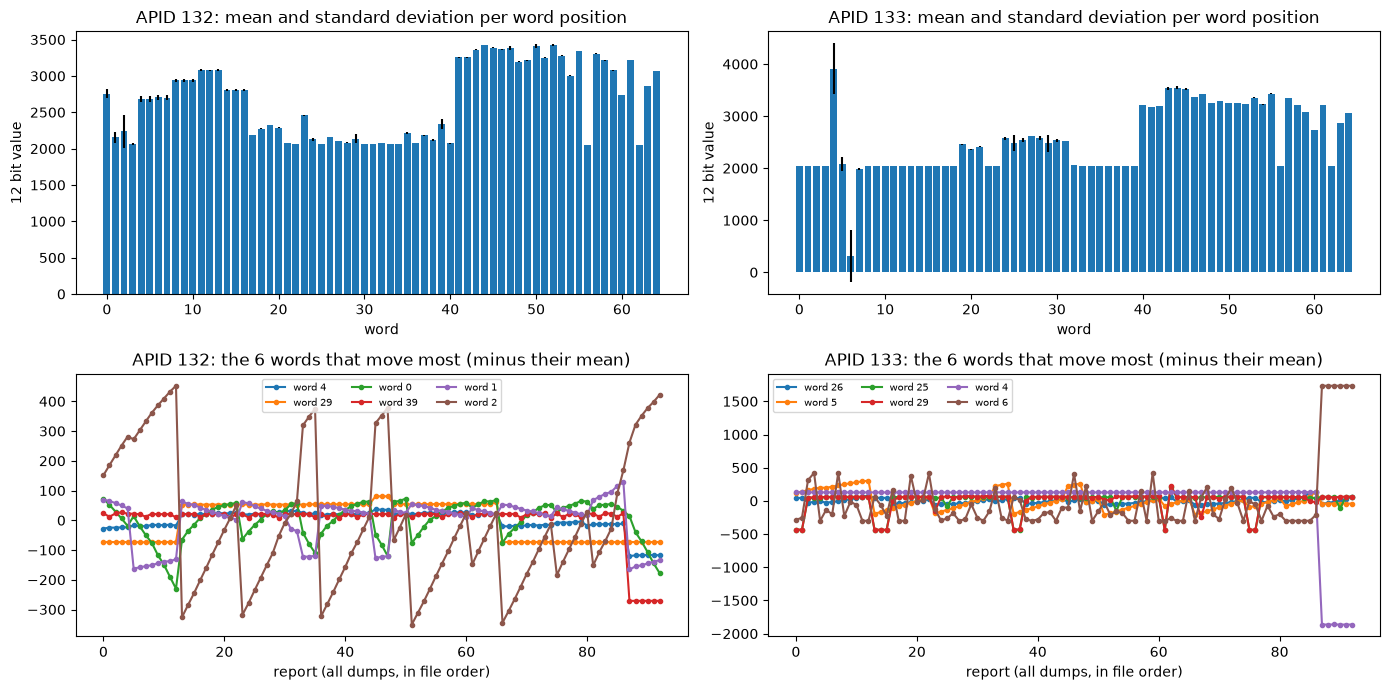

APID 132: words that sit still (std <= 1): 13 of 65
APID 133: words that sit still (std <= 1): 33 of 65
APID 133: positions that read 2048 +- 2 in more than 90 % of the reports: [0, 1, 2, 3, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 22, 23, 33, 34, 35, 36, 37, 38, 39, 56, 62]
APID 132: the same positions read: [2758, 2158, 2240, 2059, 2939, 2939, 3083, 3077, 3078, 2812, 2811, 2812, 2184, 2274, 2063, 2457, 2062, 2066, 2218, 2079, 2183, 2120, 2339, 2050, 2051]


In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
for column, apid in enumerate((132, 133)):
    values = words[apid]
    axes[0, column].bar(range(WORDS), values.mean(0), yerr=values.std(0), capsize=0)
    axes[0, column].set(
        title=f"APID {apid}: mean and standard deviation per word position", xlabel="word", ylabel="12 bit value"
    )
    moving = np.argsort(values.std(0))[-6:]
    for position in moving:
        axes[1, column].plot(values[:, position] - values[:, position].mean(), ".-", label=f"word {position}")
    axes[1, column].set(
        title=f"APID {apid}: the 6 words that move most (minus their mean)", xlabel="report (all dumps, in file order)"
    )
    axes[1, column].legend(ncol=3, fontsize=7)
plt.tight_layout()
plt.show()
for apid in (132, 133):
    print(f"APID {apid}: words that sit still (std <= 1):", int((words[apid].std(0) <= 1).sum()), "of", WORDS)
mid_scale = (np.abs(words[133] - 2048) <= 2).mean(0)
print(
    "APID 133: positions that read 2048 +- 2 in more than 90 % of the reports:",
    np.nonzero(mid_scale > 0.9)[0].tolist(),
)
print(
    "APID 132: the same positions read:",
    np.round(words[132].mean(0)[np.nonzero(mid_scale > 0.9)[0]]).astype(int).tolist(),
)

The two reports have the same layout and the same channel groups, but different values: 25 of the 65 positions sit at **2048 = mid scale** (±2) in 133 (a
bipolar input at zero, a current sensor's offset, or an unused channel), while the same words in 132 read 2 050-3 100. Words 41-57 and the last few carry 2 700-3 500 in both.
They look like **two sets of the same channels** (two units, redundant halves, or two gain ranges) and not like different quantities. In 132 and 133, 13 and 33 of the 65 positions do not move at all
(std <= 1) and the others change by a few counts to a few hundred between reports. They are slow: temperatures and bus voltages, not a science signal. Without an ICD we cannot name the channels.

## 7. What we know so far

* **APID 130:** PUS 6/6, memory dump report: four packets of 32 800 bytes (memory id `01`, start address 0, 0x8000, 0x10000, 0x18000, length 0x8000, data, CRC) = 128 KB from address 0, in a burst
  with 3 s between the packets (a second burst 180 s later in some dumps). The pieces at 0x8000, 0x10000 and 0x18000 are identical in every dump over 7 weeks (static memory:
  one dense, two 63 % zero with a repeated `00 00 02 08` pattern); the piece at 0 holds a log of about 64 records of 16 bytes (with an increasing 4 byte time tag) in front of mostly erased `0xff` and it
  is the only one that changes between dumps (and fails the CRC).
* **APID 131:** PUS 3/25, 48 bytes, 29 payload bytes of which only about six ever change: a status/configuration report, once per burst of 130.
* **APIDs 132 and 133:** PUS 3/25, 292 bytes, every 30 s for about 5 minutes per dump, same tick and sequence count: **65 words of `80 <channel> <12 bit ADC value>`** each, 133 having
  mid-scale values (2048) at many positions where 132 has readings. An analog housekeeping scan.
* All four come in the same few minutes of each ground contact (and in the same minutes as the APID 8 poll in the two dumps that have it), so they are plausibly the housekeeping and memory dump of
  the same on-board unit, whose command channel is APID 8.
* Nothing about the Sun, SWAP, LYRA, or plasma (DSLP/TPMU). Not science data.

Still open: which unit, the meaning of the 12 bit channels (no calibration, no ICD) and the structure of the pieces at 0x8000-0x18000 (a flash image?). The reports could help in the
other direction: if the temperatures or voltages are tied to the orbit position or to the Sun, they are a proxy for the attitude. That needs a position (see APID 18).